# 03 · Your own material: field notes, interviews, routes, sketch maps and many names

For an ethnographer or historian the most important data are not online: they are notes, interviews, walks,
photographs, hand-drawn maps and old documents. This notebook shows how to turn them into layers, keeping the
vagueness and multiplicity that real places have, and keeping people safe.

**All examples below are made up** for teaching. Never put real informants' details in a notebook that leaves your
computer (notebook 07).

*Running this in Google Colab?* The next cell installs the few libraries Colab lacks (about a minute). Notebooks
04-07 read files made by 01 and 02: run those first in the same session, or keep the `data` folder on Google Drive.

In [1]:
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "osmnx", "overturemaps", "mapclassify", "esda", "libpysal", "folium", "plotly"], check=True)

In [2]:
import warnings; warnings.filterwarnings("ignore")
import io
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
from shapely.geometry import Point, LineString
DATA, CRS = Path("data"), 32642

## 1. A spreadsheet of field notes becomes a layer
Keep a simple table while in the field: one row per observation, with what you know about *where*: coordinates
from a phone, or a place name, and how sure you are. Save it as CSV from Excel or Google Sheets.

In [3]:
notes_csv = """id,date,place_name,lat,lon,certainty,theme,note
1,2024-03-02,Liaquat Bazaar,,,named place,work,shopkeepers describe credit from wholesalers
2,2024-03-03,,30.2105,67.0182,GPS,mobility,women's van stop moved after road widening
3,2024-03-05,Hazara Town,,,neighbourhood,security,checkpoints described as daily routine
4,2024-03-09,,30.1748,66.9931,GPS,religion,new madrasa on former orchard land
5,2024-03-11,Quetta Railway Station,,,named place,work,porters' union meeting
6,2024-03-15,Kuchlak,,,town (approx.),migration,families from Afghanistan since the 1980s
"""
notes = pd.read_csv(io.StringIO(notes_csv))
notes

,id,date,place_name,lat,lon,certainty,theme,note
0,1,2024-03-02,Liaquat Bazaar,NaN,NaN,named place,work,shopkeepers describe credit from wholesalers
1,2,2024-03-03,NaN,30.2105,67.0182,GPS,mobility,women's van stop moved after road widening
2,3,2024-03-05,Hazara Town,NaN,NaN,neighbourhood,security,checkpoints described as daily routine
3,4,2024-03-09,NaN,30.1748,66.9931,GPS,religion,new madrasa on former orchard land
4,5,2024-03-11,Quetta Railway Station,NaN,NaN,named place,work,porters' union meeting
5,6,2024-03-15,Kuchlak,NaN,NaN,town (approx.),migration,families from Afghanistan since the 1980s


## 2. Geocoding names, and recording how good each location is
Rows without coordinates are looked up by name (OpenStreetMap's Nominatim). Every location keeps a *certainty*:
a GPS point, a named place, a neighbourhood, a town. Maps should show this, not hide it.

In [4]:
import osmnx as ox, time
for i, r in notes[notes.lat.isna()].iterrows():
    try:
        notes.loc[i, ["lat", "lon"]] = ox.geocode(f"{r.place_name}, Quetta District, Pakistan")
        notes.loc[i, "geocoded"] = "Nominatim"
    except Exception:
        notes.loc[i, "geocoded"] = "not found"
    time.sleep(1)                                   # Nominatim's rule: at most one request per second
notes["geocoded"] = notes.geocoded.fillna("GPS")
g = gpd.GeoDataFrame(notes.dropna(subset=["lat"]), geometry=gpd.points_from_xy(notes.dropna(subset=["lat"]).lon, notes.dropna(subset=["lat"]).lat), crs=4326)
g[["id", "place_name", "certainty", "geocoded", "theme"]]

,id,place_name,certainty,geocoded,theme
1,2,NaN,GPS,GPS,mobility
2,3,Hazara Town,neighbourhood,Nominatim,security
3,4,NaN,GPS,GPS,religion
4,5,Quetta Railway Station,named place,Nominatim,work
5,6,Kuchlak,town (approx.),Nominatim,migration


Uncertainty as a circle: a GPS point is a few metres, a named place a few hundred, a neighbourhood a kilometre,
a town several. Drawing the circle stops readers taking a vague place as an exact one.

In [5]:
radius = {"GPS": 20, "named place": 250, "neighbourhood": 1000, "town (approx.)": 3000}
gu = g.to_crs(CRS); gu["geometry"] = gu.buffer(gu.certainty.map(radius))
m = gu.to_crs(4326).explore(column="theme", tooltip=["date", "place_name", "certainty", "note"], tiles="Esri.WorldGrayCanvas", style_kwds={"fillOpacity": .25})
g.explore(m=m, color="black", marker_kwds={"radius": 2}, tooltip=False)
m

## 3. A walk or a journey becomes a line
From a phone's GPS track (export GPX from apps such as OsmAnd or OpenTracks), or from places in the order someone
described them. Read a GPX file with `gpd.read_file("walk.gpx", layer="tracks")`. Here a described journey:

In [6]:
journey = [("home", 67.0050, 30.1650), ("van stop", 67.0182, 30.2105), ("bazaar", 67.0080, 30.1950), ("clinic", 67.0250, 30.1900)]
route = gpd.GeoDataFrame({"who": ["respondent B (pseudonym)"], "described": ["daily route, as told in interview 7"]},
                         geometry=[LineString([(x, y) for _, x, y in journey])], crs=4326)
stops = gpd.GeoDataFrame({"stop": [s for s, *_ in journey], "order": range(1, 5)}, geometry=[Point(x, y) for _, x, y in journey], crs=4326)
print(f"route length: {route.to_crs(CRS).length.iloc[0] / 1000:.1f} km as the crow flies between stops")
m = route.explore(color="crimson", style_kwds={"weight": 4}, tiles="Esri.WorldGrayCanvas", tooltip=["who", "described"])
stops.explore(m=m, color="crimson", tooltip=["order", "stop"], marker_kwds={"radius": 6}); m

route length: 8.9 km as the crow flies between stops


## 4. Many names for one place
Places in Balochistan carry Balochi, Brahui, Pashto, Hazaragi, Urdu, Persian and English (colonial) names, and
renamings mark political change. Keep them all in a *gazetteer*: one row per place, one column per name and source.

In [7]:
gaz = pd.DataFrame([
    {"place_id": "P1", "name_official": "Quetta", "name_pashto": "کوټه (Kwaṭa)", "name_balochi": "کوئٹہ", "name_colonial": "Quetta", "note": "from Pashto kwaṭ, 'fort'"},
    {"place_id": "P2", "name_official": "Liaquat Bazaar", "name_pashto": "", "name_balochi": "", "name_colonial": "", "note": "named after Pakistan's first prime minister"},
    {"place_id": "P3", "name_official": "Hanna Lake", "name_pashto": "", "name_balochi": "", "name_colonial": "", "note": "reservoir built 1894"},
])
gaz

,place_id,name_official,name_pashto,name_balochi,name_colonial,note
0,P1,Quetta,کوټه (Kwaṭa),کوئٹہ,Quetta,"from Pashto kwaṭ, 'fort'"
1,P2,Liaquat Bazaar,,,,named after Pakistan's first prime minister
2,P3,Hanna Lake,,,,reservoir built 1894


OpenStreetMap often holds several names already (`name`, `name:ur`, `name:ps`, `name:bal`, `old_name`): see
notebook 01's places layer. Which name you print on a map is a choice (notebook 07).

## 5. A sketch map or an old map, placed on today's map (georeferencing)
A drawing by a respondent, a colonial survey sheet or a photograph of a map can be pinned to real coordinates by
matching a few points you can recognise on both (a junction, a mosque, a bridge). QGIS's *Georeferencer* does this
by clicking; in code, `rasterio` fits the transform from your control points:

```python
import rasterio
from rasterio.control import GroundControlPoint as GCP
from rasterio.transform import from_gcps
gcps = [GCP(row=120, col=80,  x=67.0035, y=30.1952),     # pixel on the scan -> lon, lat on today's map
        GCP(row=640, col=95,  x=67.0040, y=30.1801),
        GCP(row=410, col=900, x=67.0280, y=30.1870)]
with rasterio.open("sketch.png") as s:
    prof = s.profile | {"driver": "GTiff", "crs": "EPSG:4326", "transform": from_gcps(gcps)}
    with rasterio.open("sketch_georef.tif", "w", **prof) as d: d.write(s.read())
```
Then overlay it with `folium.raster_layers.ImageOverlay` or in QGIS, and trace what matters as new layers. Old maps
for the region: the Survey of India sheets (some on the David Rumsey Map Collection and in the British Library),
and colonial gazetteers such as the *Baluchistan District Gazetteer Series* (1906-07), which also hold lists of
names, tribes and settlements.

## 6. Participatory mapping
People mark their own places: where they feel safe or watched, where they work, pray, shop, were displaced from.
Use a printed map and stickers, or a shared uMap layer, then enter the marks as in section 1, with consent and with
the precision the participants agree to (notebook 07). Compare whose places appear on official maps and whose do not.

## 7. From qualitative codes to a map
If you code transcripts (in NVivo, Atlas.ti, Taguette or by hand), export a table of *code x place* and join it to
your gazetteer: where does a theme come up, and where does it not?

In [8]:
codes = pd.DataFrame({"place_name": ["Liaquat Bazaar", "Hazara Town", "Kuchlak", "Liaquat Bazaar", "Hazara Town"],
                      "code": ["debt", "checkpoints", "displacement", "checkpoints", "displacement"], "mentions": [5, 9, 7, 2, 3]})
tab = codes.pivot_table(index="place_name", columns="code", values="mentions", fill_value=0)
tab

code,checkpoints,debt,displacement
place_name,,,
Hazara Town,9.0,0.0,3.0
Kuchlak,0.0,0.0,7.0
Liaquat Bazaar,2.0,5.0,0.0


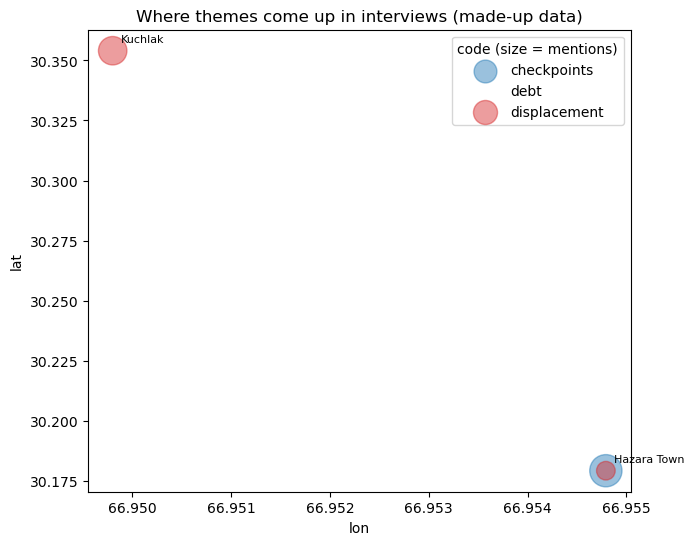

In [9]:
pts = g.dropna(subset=["place_name"]).drop_duplicates("place_name").set_index("place_name").reindex(tab.index).dropna(subset=["lat"])
fig, ax = plt.subplots(figsize=(7, 6))
for k, c in zip(tab.columns, ["C0", "C1", "C3"]):
    s = tab.loc[pts.index, k]
    ax.scatter(pts.lon, pts.lat, s=s * 60, alpha=.45, color=c, label=k)
for n, r in pts.iterrows():
    ax.annotate(n, (r.lon, r.lat), fontsize=8, xytext=(6, 6), textcoords="offset points")
ax.legend(title="code (size = mentions)"); ax.set_title("Where themes come up in interviews (made-up data)"); ax.set_xlabel("lon"); ax.set_ylabel("lat");